In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Plot settings
plt.rc('image', cmap='gray')
plt.rc('figure', autolayout=True)

Original Image Shape: (300, 300, 1)


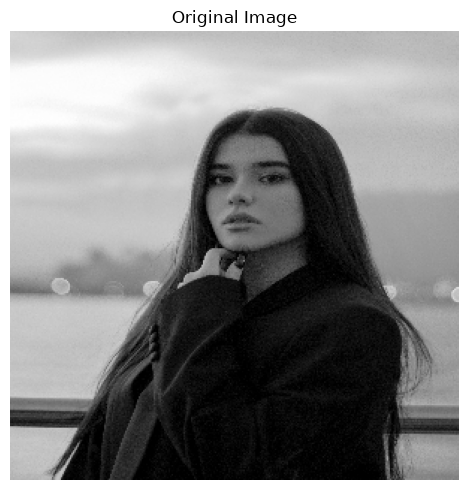

In [2]:
# Load image in grayscale and resize
image_path = "data/face_week9.jpg"
image = tf.io.read_file(image_path)
image = tf.io.decode_jpeg(image, channels=1)
image = tf.image.resize(image, [300, 300])
print("Original Image Shape:", image.shape)

# Show original image
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(image))
plt.title("Original Image")
plt.axis('off')
plt.show()
# Add batch dimension
image = tf.expand_dims(image, axis=0)

In [3]:
# Edge detection kernel
kernel = tf.constant([
[-1, -1, -1],
[-1, 8, -1],
[-1, -1, -1]
], dtype=tf.float32)
kernel = tf.reshape(kernel, [3, 3, 1, 1])

After Convolution Shape: (1, 300, 300, 1)


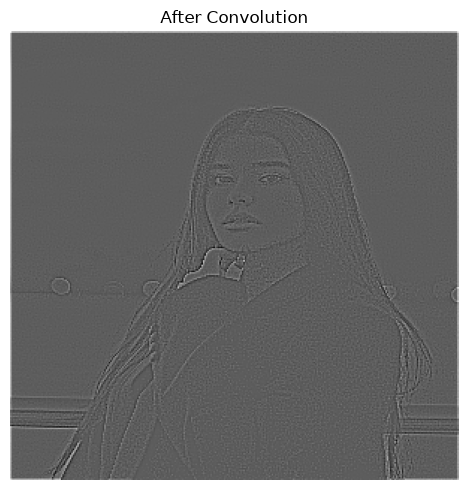

In [4]:
# Apply convolution
conv_output = tf.nn.conv2d(
input=image,
filters=kernel,
strides=[1, 1, 1, 1],
padding='SAME'
)
print("After Convolution Shape:", conv_output.shape)

# Show convolution output
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(conv_output))
plt.title("After Convolution")
plt.axis('off')
plt.show()

After ReLU Shape: (1, 300, 300, 1)


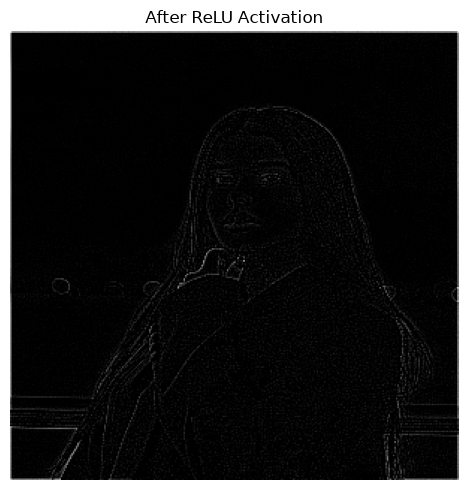

In [5]:
# Apply ReLU activation
relu_output = tf.nn.relu(conv_output)
print("After ReLU Shape:", relu_output.shape)

# Show ReLU output
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(relu_output))
plt.title("After ReLU Activation")
plt.axis('off')
plt.show()

After Pooling Shape: (1, 150, 150, 1)


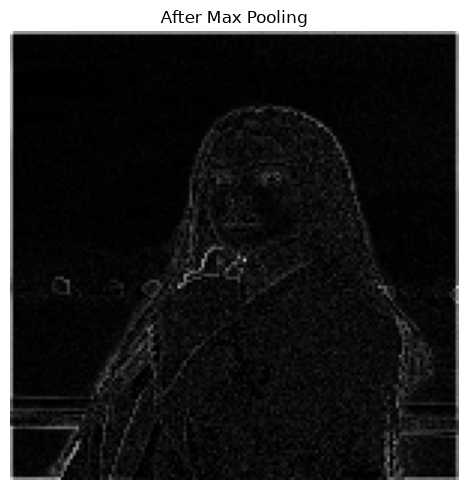

In [6]:
# Apply max pooling
pool_output = tf.nn.max_pool2d(
input=relu_output,
ksize=[1, 2, 2, 1],
strides=[1, 2, 2, 1],
padding='SAME'
)
print("After Pooling Shape:", pool_output.shape)

# Show pooling output
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(pool_output))
plt.title("After Max Pooling")
plt.axis('off')
plt.show()

In [7]:
# Flatten feature map
flatten_layer = tf.keras.layers.Flatten()
flatten_output = flatten_layer(pool_output)
print("After Flatten Shape:", flatten_output.shape)
print("First 20 Flattened Values:")
print(flatten_output.numpy()[0][:20])

After Flatten Shape: (1, 22500)
First 20 Flattened Values:
[965.25    578.8612  575.1389  577.88904 578.139   573.4722  564.3611
 577.1946  572.19434 565.8055  552.4446  551.0278  552.9724  543.88916
 544.6666  549.0555  531.889   554.6388  549.8611  536.8888 ]


In [8]:
# Fully connected layer
dense_layer = tf.keras.layers.Dense(
units=64,
activation='relu'
)
dense_output = dense_layer(flatten_output)
print("After Fully Connected Layer Shape:", dense_output.shape)

After Fully Connected Layer Shape: (1, 64)
